In [1]:
import kagglehub

# download dataset from kaggle
path = kagglehub.dataset_download("sumit12100012/loan-approval-classification")

print("Path to dataset files:", path)

100%|███████████████████████████████████████████████████████████████████████████████| 751k/751k [00:00<00:00, 9.81MB/s]

Extracting files...
Path to dataset files: C:\Users\vande\.cache\kagglehub\datasets\sumit12100012\loan-approval-classification\versions\1


In [2]:
import os
# list all files and folders in the path
files = os.listdir(path)
print("Files in dataset directory:", files)

Files in the dataset directory: ['loan_data.csv']


In [31]:
import pandas as pd

# load csv file
df = pd.read_csv('loan_data.csv')
print(df.head())

   person_age person_gender person_education  person_income  person_emp_exp  \
0        22.0        female           Master        71948.0               0   
1        21.0        female      High School        12282.0               0   
2        25.0        female      High School        12438.0               3   
3        23.0        female         Bachelor        79753.0               0   
4        24.0          male           Master        66135.0               1   

  person_home_ownership  loan_amnt loan_intent  loan_int_rate  \
0                  RENT    35000.0    PERSONAL          16.02   
1                   OWN     1000.0   EDUCATION          11.14   
2              MORTGAGE     5500.0     MEDICAL          12.87   
3                  RENT    35000.0     MEDICAL          15.23   
4                  RENT    35000.0     MEDICAL          14.27   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0                 0.49                         3.0           561  

In [49]:
has_missing = df.isnull().values.any()
print("Are there any missing values?", has_missing)

Are there any missing values? False


In [42]:
df.columns

Index(['person_age', 'person_gender', 'person_education', 'person_income',
       'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file', 'loan_status'],
      dtype='str')

In [32]:
unique_values = df['person_gender'].unique()

print(unique_values)

<ArrowStringArray>
['female', 'male']
Length: 2, dtype: str


In [33]:
unique_values = df['person_education'].unique()

print(unique_values)

<ArrowStringArray>
['Master', 'High School', 'Bachelor', 'Associate', 'Doctorate']
Length: 5, dtype: str


In [34]:
unique_values = df['person_home_ownership'].unique()

print(unique_values)

<ArrowStringArray>
['RENT', 'OWN', 'MORTGAGE', 'OTHER']
Length: 4, dtype: str


In [35]:
unique_values = df['loan_intent'].unique()

print(unique_values)

<ArrowStringArray>
[         'PERSONAL',         'EDUCATION',           'MEDICAL',
           'VENTURE',   'HOMEIMPROVEMENT', 'DEBTCONSOLIDATION']
Length: 6, dtype: str


In [36]:
unique_values = df['previous_loan_defaults_on_file'].unique()

print(unique_values)

<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


In [37]:
# separate the features from the labels
X = df.iloc[:,0:13]

# labels are 1 (loan approved) or 0 (loan not approved)
y = df.iloc[:,13]

In [38]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']
numerical_features = [col for col in X.columns if col not in categorical_features]

# when one-hot encoding, leave out one category of each categorical class, since that can be predicted from the others
preprocessor = ColumnTransformer(transformers=[
        ('num', 'passthrough', numerical_features), # 'passthrough' keeps them as-is
        ('cat', OneHotEncoder(drop='first'), categorical_features)])
transformed_X = preprocessor.fit_transform(df)

In [39]:
cat_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = numerical_features + list(cat_feature_names)
transformed_X = pd.DataFrame(transformed_df, columns=all_feature_names)
print(transformed_X.head())

   person_age  person_income  person_emp_exp  loan_amnt  loan_int_rate  \
0        22.0        71948.0             0.0    35000.0          16.02   
1        21.0        12282.0             0.0     1000.0          11.14   
2        25.0        12438.0             3.0     5500.0          12.87   
3        23.0        79753.0             0.0    35000.0          15.23   
4        24.0        66135.0             1.0    35000.0          14.27   

   loan_percent_income  cb_person_cred_hist_length  credit_score  \
0                 0.49                         3.0         561.0   
1                 0.08                         2.0         504.0   
2                 0.44                         3.0         635.0   
3                 0.44                         2.0         675.0   
4                 0.53                         4.0         586.0   

   person_gender_male  person_education_Bachelor  ...  \
0                 0.0                        0.0  ...   
1                 0.0           

In [51]:
print("Feature shape after one-hot encoding categorical columns: ", transformed_X.shape)

Feature shape after one-hot encoding categorical columns:  (45000, 22)


In [52]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

train_X, test_X, train_y, test_y = train_test_split(transformed_X, y, train_size=0.8, test_size=0.2, random_state=42)

clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(train_X, train_y)
train_acc = clf.score(train_X, train_y)
test_acc = clf.score(test_X, test_y)
print("Training error:", 1-train_acc, "Test error:", 1-test_acc)

Training error: 0.0 Test error: 0.06966666666666665


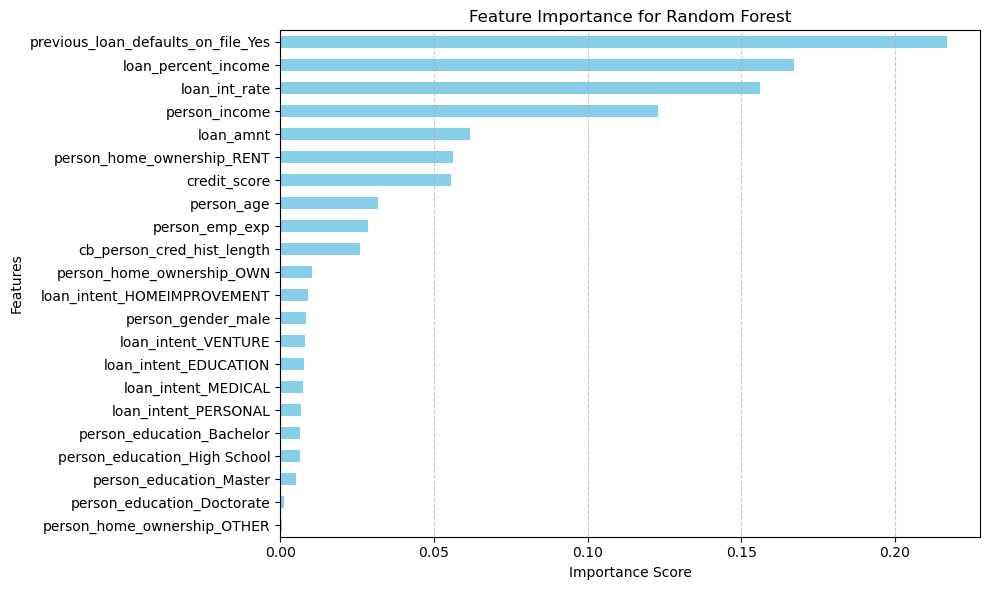

In [50]:
import matplotlib.pyplot as plt
import pandas as pd

importances = pd.Series(clf.feature_importances_, index=all_feature_names)
importances = importances.sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importances.plot(kind='barh', color='skyblue')
plt.title('Feature Importance for Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# instead of one hot encoding (too many features) use binary encodings or embeddings so quantum circuits can be simulated